In [1]:
# Transfer Learning with a Pretrained CNN
# o Load a pretrained model using VGG16.
# o Fine-tune it on a small custom dataset (e.g., cats vs dogs).
# o Freeze layers and experiment with performance

In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

I0000 00:00:1794485541.538325    8690 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794485541.616069    8690 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794485547.295059    8690 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/cats_and_dogs_filtered/train",
    image_size=(160, 160), batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/cats_and_dogs_filtered/validation",
    image_size=(160, 160), batch_size=32
)

print("Classes:", train_ds.class_names)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


E0000 00:00:1794485574.001564    8690 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [4]:
preprocess = tf.keras.applications.vgg16.preprocess_input

train_ds = train_ds.map(lambda x, y: (preprocess(x), y))
val_ds = val_ds.map(lambda x, y: (preprocess(x), y))

In [5]:
base = VGG16(weights=None, include_top=False,
              input_shape=(160, 160, 3))

base.load_weights("dataset/vgg16_weights.h5")

base.trainable = False

model = Sequential([
    base,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [6]:
h1 = model.fit(train_ds, validation_data=val_ds, epochs=3)

loss1, acc1 = model.evaluate(val_ds)

print("Frozen VGG16 Accuracy:", acc1 * 100, "%")

Epoch 1/3


/home/dhruv/.local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1794485603.471874    8905 cpu_allocator_impl.cc:82] Allocation of 209715200 exceeds 10% of free system memory.
W0000 00:00:1794485604.385902    8905 cpu_allocator_impl.cc:82] Allocation of 209715200 exceeds 10% of free system memory.
W0000 00:00:1794485605.031376    8905 cpu_allocator_impl.cc:82] Allocation of 52428800 exceeds 10% of free system memory.
W0000 00:00:1794485605.092262    8905 cpu_allocator_impl.cc:82] Allocation of 104857600 exceeds 10% of free system memory.
W0000 00:00:1794485605.193952    8905 cpu_allocator_impl.cc:82] Allocation of 104857600 exceeds 10% of free system memory.


63/63 ━━━━━━━━━━━━━━━━━━━━ 204s 3s/step - accuracy: 0.9220 - loss: 0.4188 - val_accuracy: 0.9640 - val_loss: 0.1358
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 202s 3s/step - accuracy: 0.9795 - loss: 0.0625 - val_accuracy: 0.9660 - val_loss: 0.1174
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 126s 2s/step - accuracy: 0.9910 - loss: 0.0211 - val_accuracy: 0.9650 - val_loss: 0.1087
32/32 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.9650 - loss: 0.1087
Frozen VGG16 Accuracy: 96.49999737739563 %


In [7]:
base.trainable = True

for layer in base.layers[:-4]:
    layer.trainable = False

model.compile(optimizer=Adam(learning_rate=0.00001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

h2 = model.fit(train_ds, validation_data=val_ds, epochs=3)

loss2, acc2 = model.evaluate(val_ds)

print("Fine-tuned VGG16 Accuracy:", acc2 * 100, "%")

Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 159s 2s/step - accuracy: 0.9970 - loss: 0.0107 - val_accuracy: 0.9650 - val_loss: 0.1255
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.9990 - loss: 0.0032 - val_accuracy: 0.9650 - val_loss: 0.1208
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 154s 2s/step - accuracy: 0.9990 - loss: 0.0029 - val_accuracy: 0.9590 - val_loss: 0.1512
32/32 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.9590 - loss: 0.1512
Fine-tuned VGG16 Accuracy: 95.89999914169312 %


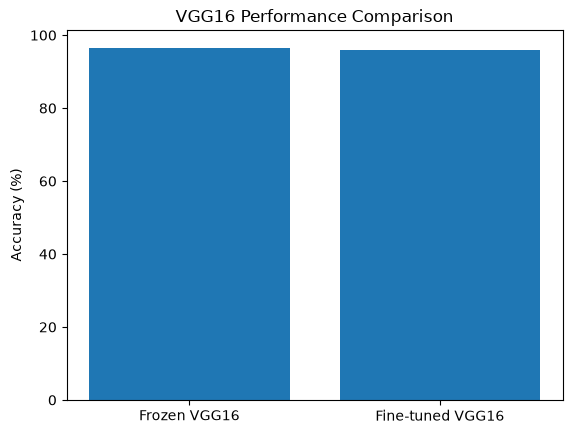

In [8]:
# compare
plt.bar(['Frozen VGG16', 'Fine-tuned VGG16'],
        [acc1 * 100, acc2 * 100])

plt.ylabel("Accuracy (%)")
plt.title("VGG16 Performance Comparison")
plt.show()

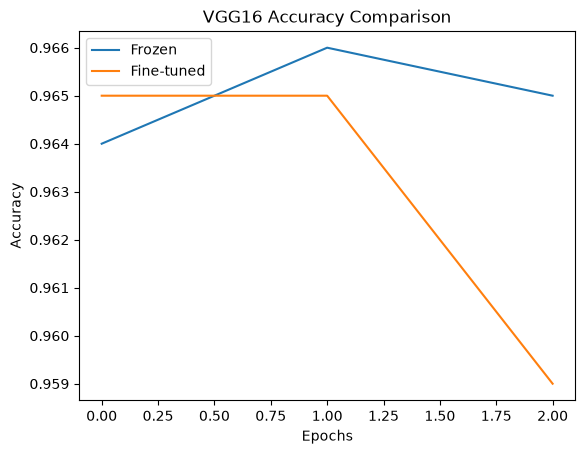

In [9]:
# plot
plt.plot(h1.history['val_accuracy'], label='Frozen')
plt.plot(h2.history['val_accuracy'], label='Fine-tuned')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("VGG16 Accuracy Comparison")
plt.legend()
plt.show()